# Integration, Taylor Approximation, and Calculus for ML

**AI Mathematics · 2. Calculus**

Cover integrals as accumulation and expectation, plus Taylor approximation, convexity, and first- and second-order optimality.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Approximate definite integrals numerically.
- Connect expectations and marginalization to integration.
- Use Taylor expansions and local optimality conditions.

In [1]:
import numpy as np

## 1. Indefinite and definite integrals
An indefinite integral describes antiderivatives; a definite integral accumulates area or mass over an interval. In probability, integrating a density over a region gives probability, and integrating a function against a density gives expectation.

In [2]:
import numpy as np

# Integral of x^2 from 0 to 1 is 1/3. Approximate by a Riemann sum.
x = np.linspace(0.0, 1.0, 100_001)
y = x**2
area = np.trapezoid(y, x)
print("numerical integral:", area)
print("exact value:", 1/3)

numerical integral: 0.3333333333499999
exact value: 0.3333333333333333


## 2. Expectations and marginalization
For a continuous random variable with density \(p(x)\), \(\mathbb{E}[g(X)]=\int g(x)p(x)dx\). A joint density can be marginalized by integrating out a variable: \(p(x)=\int p(x,y)dy\). Discrete distributions use sums instead of integrals.

In [3]:
# Approximate E[X^2] for X ~ Uniform(0,1) by Monte Carlo sampling
rng = np.random.default_rng(42)
samples = rng.uniform(0.0, 1.0, size=200_000)
print("estimated E[X^2]:", np.mean(samples**2))
print("exact E[X^2]:", 1/3)

estimated E[X^2]: 0.333306815282796
exact E[X^2]: 0.3333333333333333


## 3. Taylor expansion
Near \(x_0\), a smooth function can be approximated by a polynomial. The first-order expansion is \(f(x)\approx f(x_0)+f'(x_0)(x-x_0)\); the second-order expansion adds curvature. In multiple dimensions, the quadratic term uses the Hessian.

In [4]:
def f(x): return np.exp(x)
x0, x = 0.0, 0.2
first_order = f(x0) + f(x0)*(x-x0)
second_order = f(x0) + f(x0)*(x-x0) + 0.5*f(x0)*(x-x0)**2
print("true:", f(x))
print("first-order:", first_order)
print("second-order:", second_order)

true: 1.2214027581601699
first-order: 1.2
second-order: 1.22


## 4. Convexity and optimality
For a differentiable unconstrained function, a local minimum must have zero gradient, but zero gradient alone is not sufficient. For twice-differentiable convex functions, a positive-semidefinite Hessian is a local curvature condition; for a globally convex function, any stationary point is a global minimizer. Neural-network losses are generally nonconvex.

In [5]:
def quadratic(x):
    return 0.5 * x @ np.array([[2.0, 0.0], [0.0, 4.0]]) @ x

x = np.array([1.0, -1.0])
grad = np.array([[2.0, 0.0], [0.0, 4.0]]) @ x
print("loss:", quadratic(x))
print("gradient:", grad)

# A stationary point can also be a saddle; inspect curvature/eigenvalues.
H_saddle = np.diag([2.0, -2.0])
print("saddle Hessian eigenvalues:", np.linalg.eigvalsh(H_saddle))

loss: 3.0
gradient: [ 2. -4.]
saddle Hessian eigenvalues: [-2.  2.]


### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Practical lab: numerical integration and Taylor approximation

A definite integral accumulates area. When an antiderivative is not convenient, the trapezoidal rule approximates the area using line segments. Increasing the number of subintervals often improves the estimate for a smooth function, but floating-point effects and the function's behavior still matter.

08_integration_taylor_and_calculus_for_ml.ipynb:cell13:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
08_integration_taylor_and_calculus_for_ml.ipynb:cell13:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,subintervals,trapezoid estimate
0,4,0.880619
1,8,0.881704
2,16,0.881986
3,32,0.882058
4,64,0.882075
5,128,0.882080
6,256,0.882081


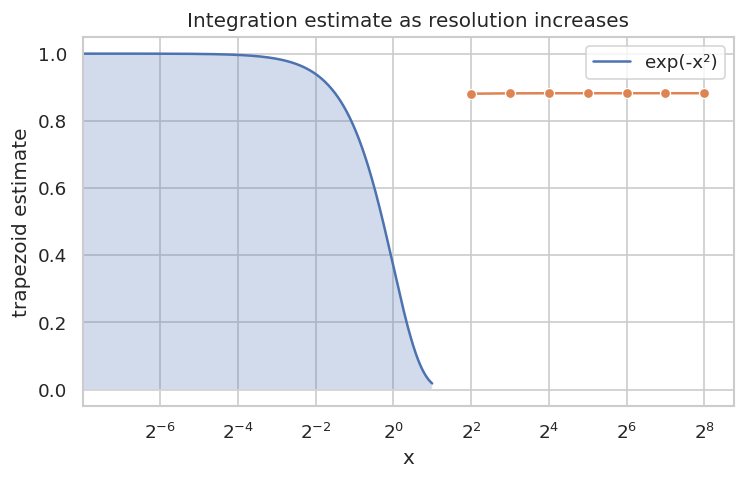

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
def viz_int_f(t):
    return np.exp(-t*t)
viz_int_a, viz_int_b = 0.0, 2.0
viz_int_x = np.linspace(viz_int_a, viz_int_b, 300)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(viz_int_x, viz_int_f(viz_int_x), label="exp(-x²)")
ax.fill_between(viz_int_x, viz_int_f(viz_int_x), alpha=0.25)
ax.set_title("A definite integral as accumulated area"); ax.set_xlabel("x"); ax.legend(); plt.show()
viz_int_ns = np.array([4, 8, 16, 32, 64, 128, 256])
viz_int_est = [np.trapezoid(viz_int_f(np.linspace(viz_int_a, viz_int_b, int(n)+1)), np.linspace(viz_int_a, viz_int_b, int(n)+1)) for n in viz_int_ns]
viz_int_table = pd.DataFrame({"subintervals": viz_int_ns, "trapezoid estimate": viz_int_est})
display(viz_int_table.round(7))
sns.lineplot(data=viz_int_table, x="subintervals", y="trapezoid estimate", marker="o")
plt.xscale("log", base=2); plt.title("Integration estimate as resolution increases"); plt.show()

### Approximate a nonlinear function locally

A first-order Taylor approximation uses the tangent line; a second-order approximation also uses curvature. Taylor approximations are local, not global guarantees. In machine learning, local approximations help explain gradient-based updates and second-order optimization.

08_integration_taylor_and_calculus_for_ml.ipynb:cell15:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


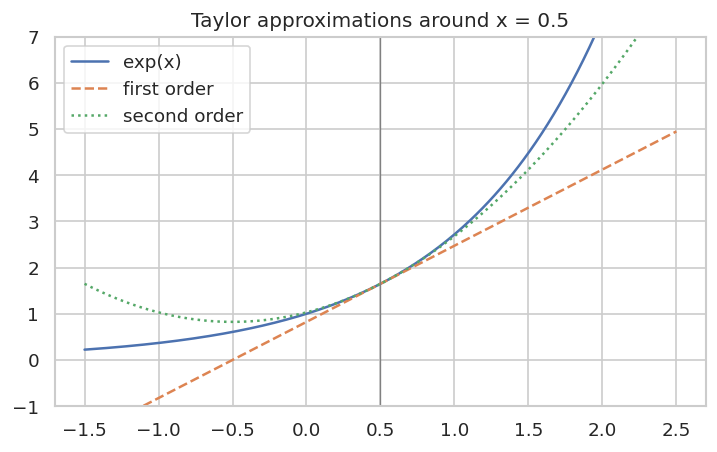

In [7]:
viz_tay_x0 = 0.5
viz_tay_grid = np.linspace(-1.5, 2.5, 300)
viz_tay_f = np.exp(viz_tay_grid)
viz_tay_y0 = np.exp(viz_tay_x0)
viz_tay_first = viz_tay_y0 * (1 + (viz_tay_grid-viz_tay_x0))
viz_tay_second = viz_tay_y0 * (1 + (viz_tay_grid-viz_tay_x0) + 0.5*(viz_tay_grid-viz_tay_x0)**2)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(viz_tay_grid, viz_tay_f, label="exp(x)")
ax.plot(viz_tay_grid, viz_tay_first, "--", label="first order")
ax.plot(viz_tay_grid, viz_tay_second, ":", label="second order")
ax.axvline(viz_tay_x0, color="0.5", lw=0.8); ax.set_ylim(-1, 7); ax.legend(); ax.set_title("Taylor approximations around x = 0.5"); plt.show()

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Estimate the integral of 3*x^2 on [0, 2].

In [8]:
x = np.linspace(0, 2, 10001)
print(np.trapezoid(3*x**2, x))  # exact: 8

8.00000004


### Exercise 2
Exercise 2: For f(x)=x^2, write the second-order Taylor approximation at x0=1.

In [9]:
x0, x = 1.0, 1.2
approx = x0**2 + 2*x0*(x-x0) + (x-x0)**2
print(approx, "true:", x**2)

1.44 true: 1.44


## Key takeaways
- Integration links densities to probabilities and functions to expectations.
- Taylor expansions provide local approximations of smooth functions.
- A zero gradient does not distinguish minima, maxima, and saddle points; curvature matters.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.